In [ ]:
# !pip install transformers datasets torch scikit-learn pandas numpy matplotlib seaborn tqdm
# !pip install accelerate -U  # For faster training

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup,
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings

In [ ]:
SEED = 10
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Check for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cpu


In [ ]:
INTENT_CATEGORIES = {
    0: 'Request',
    1: 'Meeting',
    2: 'Follow-up',
    3: 'Complaint',
    4: 'Spam'
}

NUM_LABELS = len(INTENT_CATEGORIES)
print(f"Number of intent categories: {NUM_LABELS}")
print("Categories:", INTENT_CATEGORIES)

Number of intent categories: 5
Categories: {0: 'Request', 1: 'Meeting', 2: 'Follow-up', 3: 'Complaint', 4: 'Spam'}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# df = pd.read_csv('drive/MyDrive/CS470 Email Intent Project/email_intents.csv')
df = pd.read_csv('drive/MyDrive/CS470 Email Intent Project/email_intents.csv')

# Create label mapping
label_mapping = {
    'Request': 0,
    'Meeting': 1,
    'Follow-up': 2,
    'Complaint': 3,
    'Spam': 4
}

# Apply mapping
df['label_numeric'] = df['label'].map(label_mapping)

print(df.head())

                                                text      label  label_numeric
0         URGENT: verify now to protect your device.       Spam              4
1  I'd like to arrange a video call on June 12 to...    Meeting              1
2  I'd like to arrange a video call next week to ...    Meeting              1
3  I'm disappointed with the unprofessional behav...  Complaint              3
4  I'm disappointed with the missed deadlines we'...  Complaint              3


### Split Data for Train, Val, Test

In [ ]:
# Split data: 70% train, 15% validation, 15% test
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    random_state=SEED,
    stratify=df['label_numeric']  # Use label_numeric for stratification
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df['label_numeric']  # Use label_numeric for stratification
)

print(f"\nTraining samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")



Training samples: 875
Validation samples: 187
Test samples: 188


In [ ]:
# Create TF-IDF features
print("Training baseline model\n")

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(train_df['text'])
X_val_tfidf = tfidf.transform(val_df['text'])
X_test_tfidf = tfidf.transform(test_df['text'])

# Train logistic regression
baseline_model = LogisticRegression(max_iter=1000, random_state=SEED)
baseline_model.fit(X_train_tfidf, train_df['label'])

# Evaluate baseline
train_preds = baseline_model.predict(X_train_tfidf)
val_preds = baseline_model.predict(X_val_tfidf)
test_preds = baseline_model.predict(X_test_tfidf)

Training baseline model



### Prepare Data for Distill-BERT

In [ ]:
# Load the pre-trained DistilBERT tokenizer
# This tokenizer will convert text into tokens that the model can understand
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

# Create a custom PyTorch Dataset class for email data
# This class handles tokenization and prepares data in the format PyTorch expects
class EmailDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        # Get the text and label at the specified index
        text = str(self.texts[idx])
        label = self.labels[idx]

        # Tokenize the text using DistilBERT tokenizer
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,      # Add [CLS] and [SEP] tokens
            max_length=self.max_length,   # Truncate or pad to max_length
            padding='max_length',          # Pad shorter sequences to max_length
            truncation=True,               # Truncate longer sequences to max_length
            return_attention_mask=True,    # Return attention mask (1 for real tokens, 0 for padding)
            return_tensors='pt'            # Return PyTorch tensors
        )

        # Return dictionary with flattened tensors
        # flatten() removes the batch dimension added by return_tensors='pt'
        return {
            'input_ids': encoding['input_ids'].flatten(),           # Token IDs
            'attention_mask': encoding['attention_mask'].flatten(), # Attention mask
            'label': torch.tensor(label, dtype=torch.long)          # Convert label to tensor
        }

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:

# Create datasets - USE label_numeric instead of label
train_dataset = EmailDataset(
    train_df['text'].values,
    train_df['label_numeric'].values,  # Changed from 'label' to 'label_numeric'
    tokenizer
)

val_dataset = EmailDataset(
    val_df['text'].values,
    val_df['label_numeric'].values,  # Changed from 'label' to 'label_numeric'
    tokenizer
)

test_dataset = EmailDataset(
    test_df['text'].values,
    test_df['label_numeric'].values,  # Changed from 'label' to 'label_numeric'
    tokenizer
)


In [ ]:
# Create Dataloaders

BATCH_SIZE = 16

print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Recreate DataLoaders with the updated datasets
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Train dataset size: 875
Validation dataset size: 187
Test dataset size: 188


### Load and Configure Pre-trained Model

In [ ]:
# Load pre-trained DistilBERT for sequence classification
model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased',
    num_labels=NUM_LABELS
)

model.to(device)

print(f"Model loaded and moved to {device}")
print(f"\nNumber of parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded and moved to cpu

Number of parameters: 66,957,317
Trainable parameters: 66,957,317


In [ ]:
from torch.optim import AdamW

EPOCHS = 3 # seems like max required is actually 3
LEARNING_RATE = 2e-5
WARMUP_STEPS = 100

# Optimizer
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, eps=1e-8)

# Learning rate scheduler
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=total_steps
)

print(f"Total training steps: {total_steps}")
print(f"Warmup steps: {WARMUP_STEPS}")

Total training steps: 165
Warmup steps: 100


### Configure Training Functions

In [ ]:
def train_epoch(model, data_loader, optimizer, scheduler, device):
    # training for one epoch
    model.train()
    total_loss = 0
    predictions = []
    true_labels = []

    progress_bar = tqdm(data_loader, desc="Training")

    for batch in progress_bar:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        total_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        preds = torch.argmax(outputs.logits, dim=1)
        predictions.extend(preds.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

        progress_bar.set_postfix({'loss': loss.item()})

    avg_loss = total_loss / len(data_loader)
    accuracy = accuracy_score(true_labels, predictions)

    return avg_loss, accuracy

In [ ]:
def evaluate(model, data_loader, device):
    # Evaluate performance of model
    model.eval()
    total_loss = 0
    predictions = []
    true_labels = []

    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Evaluating"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            total_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    accuracy = accuracy_score(true_labels, predictions)

    return avg_loss, accuracy, predictions, true_labels

# Training Model!


In [ ]:
# Training history
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

# Early stopping parameters
best_val_acc = 0
patience = 2 # max could be 2 without any trouble
patience_counter = 0

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # Train
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, device)
    print(f"Training Loss: {train_loss:.4f}, Accuracy: {train_acc:.4f}")

    # Validate
    val_loss, val_acc, _, _ = evaluate(model, val_loader, device)
    print(f"Validation Loss: {val_loss:.4f}, Accuracy: {val_acc:.4f}")

    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Early stopping
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        # Save best model
        torch.save(model.state_dict(), 'best_model.pt')
        print(f"Saved new model (Val Acc: {best_val_acc:.4f})")
    else:
        patience_counter += 1
        print(f"No improvement: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print("\nEarly stopping triggered!")
            break

print("Done.")
print(f"Best validation accuracy: {best_val_acc:.4f}")


Epoch 1/3


Training: 100%|██████████| 55/55 [12:33<00:00, 13.70s/it, loss=1.27]


Training Loss: 1.5509, Accuracy: 0.3817


Evaluating: 100%|██████████| 12/12 [00:42<00:00,  3.57s/it]


Validation Loss: 1.3100, Accuracy: 0.9358
Saved new model (Val Acc: 0.9358)

Epoch 2/3


...

Validation Loss: 0.1109, Accuracy: 0.9947
Saved new model (Val Acc: 0.9947)

Epoch 3/3


Training: 100%|██████████| 55/55 [11:38<00:00, 12.69s/it, loss=0.0467]


Training Loss: 0.0634, Accuracy: 0.9977


Evaluating: 100%|██████████| 12/12 [00:40<00:00,  3.39s/it]

Validation Loss: 0.0451, Accuracy: 0.9947
No improvement: 1/2
Done.
Best validation accuracy: 0.9947


In [ ]:
# Load best model
model.load_state_dict(torch.load('best_model.pt'))

# Evaluate on test set
test_loss, test_acc, test_predictions, test_true_labels = evaluate(model, test_loader, device)

print(f"\nTest Set Performance:")
print(f"Loss: {test_loss:.4f}")
print(f"Accuracy: {test_acc:.4f}")

Evaluating: 100%|██████████| 12/12 [00:43<00:00,  3.59s/it]


Test Set Performance:
Loss: 0.0991
Accuracy: 1.0000


In [ ]:
# Detailed metrics
print(classification_report(
    test_true_labels,
    test_predictions,
    target_names=list(INTENT_CATEGORIES.values())
))

              precision    recall  f1-score   support

     Request       1.00      1.00      1.00        38
     Meeting       1.00      1.00      1.00        38
   Follow-up       1.00      1.00      1.00        37
   Complaint       1.00      1.00      1.00        37
        Spam       1.00      1.00      1.00        38

    accuracy                           1.00       188
   macro avg       1.00      1.00      1.00       188
weighted avg       1.00      1.00      1.00       188



# Test Content Classification Success

In [ ]:
def predict_email_intent(text, model, tokenizer, device):
    model.eval()
    encoding = tokenizer(
        text,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)

    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        probabilities = torch.softmax(logits, dim=1)
        predicted_class = torch.argmax(probabilities, dim=1).item()

    return {
        'predicted_intent': INTENT_CATEGORIES[predicted_class],
        'confidence': probabilities[0][predicted_class].item(),
        'all_probabilities': {INTENT_CATEGORIES[i]: probabilities[0][i].item() for i in range(NUM_LABELS)}
    }

test_emails = [
    "Can you please send me the latest sales figures?",
    "Let's schedule a meeting for next week to discuss the project.",
    "I wanted to follow up on my previous email about the budget.",
    "I'd like to have a change of room service.",
    "CS470 is the best class",
    "Want a chance to win a $100 Gift Card?",
    "Send me your password",
    "Buy now and get 50% off!!"
]

for email in test_emails:
    result = predict_email_intent(email, model, tokenizer, device)
    print(f"Email: {email}")
    print(f"Predicted Intent: {result['predicted_intent']}")
    print(f"Confidence: {result['confidence']:.4f}")
    print("-" * 80)

Email: Can you please send me the latest sales figures?
Predicted Intent: Request
Confidence: 0.8721
--------------------------------------------------------------------------------
Email: Let's schedule a meeting for next week to discuss the project.
Predicted Intent: Meeting
Confidence: 0.9117
--------------------------------------------------------------------------------
Email: I wanted to follow up on my previous email about the budget.
Predicted Intent: Follow-up
Confidence: 0.7378
--------------------------------------------------------------------------------
Email: I'd like to have a change of room service.
Predicted Intent: Request
Confidence: 0.6439
--------------------------------------------------------------------------------
Email: CS470 is the best class
Predicted Intent: Spam
Confidence: 0.4134
--------------------------------------------------------------------------------
Email: Want a chance to win a $100 Gift Card?
Predicted Intent: Spam
Confidence: 0.4942
--------

In [ ]:
# Save model and tokenizer
model.save_pretrained('./email_intent_classifier')
tokenizer.save_pretrained('./email_intent_classifier')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./email_intent_classifier/tokenizer_config.json',
 './email_intent_classifier/tokenizer.json')

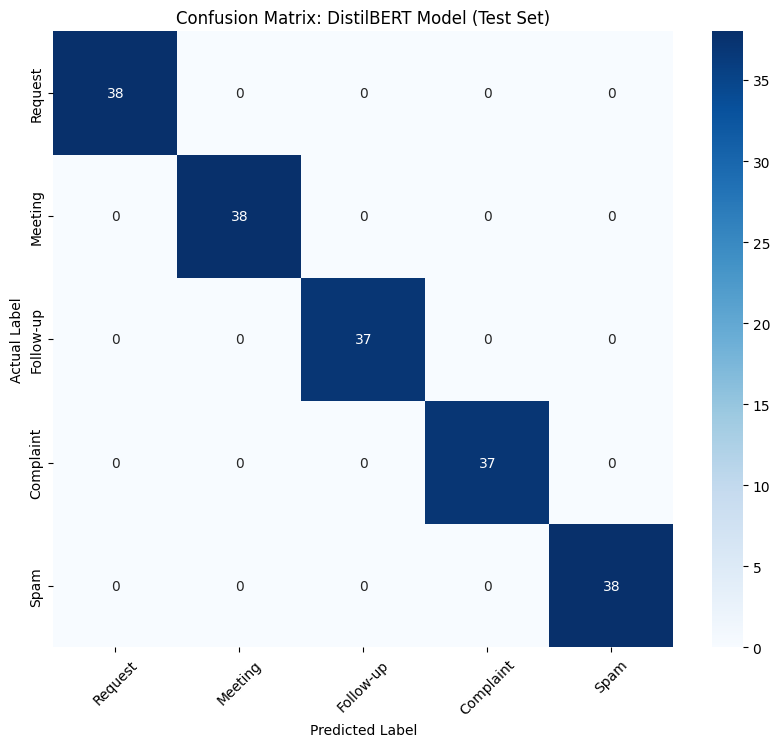

In [ ]:
class_names = [INTENT_CATEGORIES[i] for i in range(len(INTENT_CATEGORIES))]
cm = confusion_matrix(test_true_labels, test_predictions)

# 2. Plotting using Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix: DistilBERT Model (Test Set)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45)
plt.show()

row_sums = cm.sum(axis=1, keepdims=True)
norm_cm = cm / row_sums # Normalize to see percentages if needed
np.fill_diagonal(cm, 0) # Zero out correct predictions to find max error
max_confusion_idx = np.unravel_index(np.argmax(cm, axis=None), cm.shape)
